# Retail Promotion Effectiveness & Discount Sensitivity Analysis
## 01 — Data Audit

Inventories the supplied dunnhumby files, validates real schemas and relationships, documents cleaning, and creates the downstream analytical table. Raw files are read-only.

## Imports

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)

## Config (file paths, plotting style, and reproducibility)

In [2]:
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').exists():
            return candidate
    raise FileNotFoundError('Run from the repository or notebooks directory.')
PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_utils import add_bar_labels, add_promotion_fields, bootstrap_ci, summarize_frame
RANDOM_STATE = 42
ALPHA = 0.05
POWER = 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

## Data Cleaning and Preprocessing

Missing rows are counted before documented `dropna`; exact duplicates and verified keys are checked separately. No raw file is modified.

In [3]:
required_files = ['transaction_data.csv','product.csv','hh_demographic.csv','coupon.csv','coupon_redempt.csv','campaign_table.csv','campaign_desc.csv','causal_data.csv']
inventory = pd.DataFrame({'file_name': required_files})
inventory['exists'] = inventory['file_name'].map(lambda name: (RAW_DIR / name).exists())
inventory['size_mb'] = inventory['file_name'].map(lambda name: round((RAW_DIR / name).stat().st_size / 1_048_576, 2) if (RAW_DIR / name).exists() else np.nan)
display(inventory)
assert inventory['exists'].all(), 'Required source files are missing.'

,file_name,exists,size_mb
0,transaction_data.csv,True,135.18
1,product.csv,True,6.13
2,hh_demographic.csv,True,0.04
3,coupon.csv,True,2.69
4,coupon_redempt.csv,True,0.05
5,campaign_table.csv,True,0.09
6,campaign_desc.csv,True,0.00
7,causal_data.csv,True,663.62


In [4]:
transactions = pd.read_csv(RAW_DIR / 'transaction_data.csv', low_memory=False)
products = pd.read_csv(RAW_DIR / 'product.csv', low_memory=False)
households = pd.read_csv(RAW_DIR / 'hh_demographic.csv', low_memory=False)
coupons = pd.read_csv(RAW_DIR / 'coupon.csv', low_memory=False)
redemptions = pd.read_csv(RAW_DIR / 'coupon_redempt.csv', low_memory=False)
campaigns = pd.read_csv(RAW_DIR / 'campaign_table.csv', low_memory=False)
campaign_desc = pd.read_csv(RAW_DIR / 'campaign_desc.csv', low_memory=False)

In [5]:
summarize_frame('transaction_data', transactions, 'SALES_VALUE')

transaction_data row count: 2,595,732
transaction_data column count: 12
transaction_data null counts:
household_key        0
BASKET_ID            0
DAY                  0
PRODUCT_ID           0
QUANTITY             0
SALES_VALUE          0
STORE_ID             0
RETAIL_DISC          0
TRANS_TIME           0
WEEK_NO              0
COUPON_DISC          0
COUPON_MATCH_DISC    0


transaction_data exact duplicate count: 0
transaction_data DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB
transaction_data descriptive statistics for SALES_VALUE:
count    2.595732e+06
mean     3.104120e+00
std      4.182274e+00
min      0.000000e+00
25%      1.290000e+00
50%      2.000000e+00
75%      3.490000e+00
max      8.400000e+02


In [6]:
print('Rows with any missing source value:', f'{transactions.isna().any(axis=1).sum():,}')
transactions_clean = transactions.dropna().drop_duplicates().copy()
print('Rows after documented dropna and exact deduplication:', f'{len(transactions_clean):,}')
print('No single-row ID exists; basket/product repetitions may be legitimate lines.')

Rows with any missing source value: 0


Rows after documented dropna and exact deduplication: 2,595,732
No single-row ID exists; basket/product repetitions may be legitimate lines.


In [7]:
specs = {
 'product': (products, 'PRODUCT_ID', ['PRODUCT_ID']),
 'hh_demographic': (households, 'household_key', ['household_key']),
 'coupon': (coupons, 'CAMPAIGN', ['COUPON_UPC','PRODUCT_ID','CAMPAIGN']),
 'coupon_redempt': (redemptions, 'DAY', None),
 'campaign_table': (campaigns, 'CAMPAIGN', ['household_key','CAMPAIGN']),
 'campaign_desc': (campaign_desc, 'CAMPAIGN', ['CAMPAIGN'])}
quality = []
for name, (frame, numeric, key) in specs.items():
    print(f'\n--- {name} ---')
    summarize_frame(name, frame, numeric, key)
    quality.append({'table':name,'rows':len(frame),'columns':frame.shape[1],'null_cells':int(frame.isna().sum().sum()),'exact_duplicates':int(frame.duplicated().sum())})


--- product ---
product row count: 92,353
product column count: 7
product null counts:
PRODUCT_ID              0
MANUFACTURER            0
DEPARTMENT              0
BRAND                   0
COMMODITY_DESC          0
SUB_COMMODITY_DESC      0
CURR_SIZE_OF_PRODUCT    0
product exact duplicate count: 0
product duplicate count on verified key ['PRODUCT_ID']: 0
product DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 92353 entries, 0 to 92352
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   PRODUCT_ID            92353 non-null  int64
 1   MANUFACTURER          92353 non-null  int64
 2   DEPARTMENT            92353 non-null  str  
 3   BRAND                 92353 non-null  str  
 4   COMMODITY_DESC        92353 non-null  str  
 5   SUB_COMMODITY_DESC    92353 non-null  str  
 6   CURR_SIZE_OF_PRODUCT  92353 non-null  str  
dtypes: int64(2), str(5)
memory usage: 9.5 MB
product descriptive statistics 

In [8]:
causal_rows = 0
causal_nulls = None
causal_chunk_duplicates = 0
for chunk in pd.read_csv(RAW_DIR / 'causal_data.csv', chunksize=2_000_000, dtype=str):
    causal_rows += len(chunk)
    causal_nulls = chunk.isna().sum() if causal_nulls is None else causal_nulls.add(chunk.isna().sum(), fill_value=0)
    causal_chunk_duplicates += int(chunk.duplicated().sum())
print('causal_data row count:', f'{causal_rows:,}')
print('causal_data column count:', len(chunk.columns))
print('causal_data null counts:\n' + causal_nulls.astype(int).to_string())
print('causal_data exact duplicates detected within chunks:', f'{causal_chunk_duplicates:,}')
sample = pd.read_csv(RAW_DIR / 'causal_data.csv', nrows=100_000, low_memory=False)
sample.info()
print(sample['WEEK_NO'].describe().to_string())
print('A global duplicate/key check was not materialized for the unused 696 MB table; the reported chunk checks are exact within each chunk.')

causal_data row count: 36,786,524
causal_data column count: 5
causal_data null counts:
PRODUCT_ID    0
STORE_ID      0
WEEK_NO       0
display       0
mailer        0
causal_data exact duplicates detected within chunks: 0
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   PRODUCT_ID  100000 non-null  int64
 1   STORE_ID    100000 non-null  int64
 2   WEEK_NO     100000 non-null  int64
 3   display     100000 non-null  str  
 4   mailer      100000 non-null  str  
dtypes: int64(3), str(2)
memory usage: 4.0 MB
count    100000.00000
mean         54.21372
std          26.77372
min           9.00000
25%          31.00000
50%          56.00000
75%          77.00000
max         101.00000
A global duplicate/key check was not materialized for the unused 696 MB table; the reported chunk checks are exact within each chunk.


In [9]:
assert products['PRODUCT_ID'].is_unique
transaction_product = transactions_clean.merge(products, on='PRODUCT_ID', how='left', validate='many_to_one', indicator=True)
print(transaction_product['_merge'].value_counts(dropna=False).to_string())
unmatched_products = int((transaction_product['_merge'] != 'both').sum())
print('Unmatched transaction rows:', f'{unmatched_products:,}')
transaction_product = transaction_product.drop(columns='_merge')

_merge
both          2595732
left_only           0
right_only          0
Unmatched transaction rows: 0


In [10]:
transaction_product = add_promotion_fields(transaction_product)
print('DAY range:', transactions_clean.DAY.min(), 'to', transactions_clean.DAY.max())
print('WEEK_NO range:', transactions_clean.WEEK_NO.min(), 'to', transactions_clean.WEEK_NO.max())
print('Quantity percentiles (retained):\n' + transactions_clean.QUANTITY.quantile([0,.5,.95,.99,.999,1]).to_string())
print('Positive RETAIL_DISC adjustments retained:', int((transactions_clean.RETAIL_DISC > 0).sum()))
print('There is no verified cost or margin column.')

DAY range: 1 to 711
WEEK_NO range: 1 to 102
Quantity percentiles (retained):
0.000        0.000
0.500        1.000
0.950        3.000
0.990       10.000
0.999    16943.538
1.000    89638.000
Positive RETAIL_DISC adjustments retained: 36
There is no verified cost or margin column.


In [11]:
transaction_product.to_csv(PROCESSED_DIR / 'transaction_product_analysis.csv.gz', index=False, compression='gzip')
inventory.to_csv(PROCESSED_DIR / 'source_inventory.csv', index=False)
pd.DataFrame(quality).to_csv(PROCESSED_DIR / 'data_quality_summary.csv', index=False)
print('Processed rows written:', f'{len(transaction_product):,}')

Processed rows written: 2,595,732


## Column Description

One line per column with observed type; derived fields are labeled.

In [12]:
derived = {'discount_amount','gross_value_proxy','discount_rate','promotion_type','is_discounted'}
display(pd.DataFrame({'column':transaction_product.columns,'type':transaction_product.dtypes.astype(str).values,'origin':['Derived' if x in derived else 'Source' for x in transaction_product.columns]}))

,column,type,origin
0,household_key,int64,Source
1,BASKET_ID,int64,Source
2,DAY,int64,Source
3,PRODUCT_ID,int64,Source
4,QUANTITY,int64,Source
5,SALES_VALUE,float64,Source
6,STORE_ID,int64,Source
7,RETAIL_DISC,float64,Source
8,TRANS_TIME,int64,Source
9,WEEK_NO,int64,Source


## EDA

The row-count chart uses a log scale because table sizes differ by orders of magnitude. The sales histogram is display-capped at the 99th percentile; data is not removed.

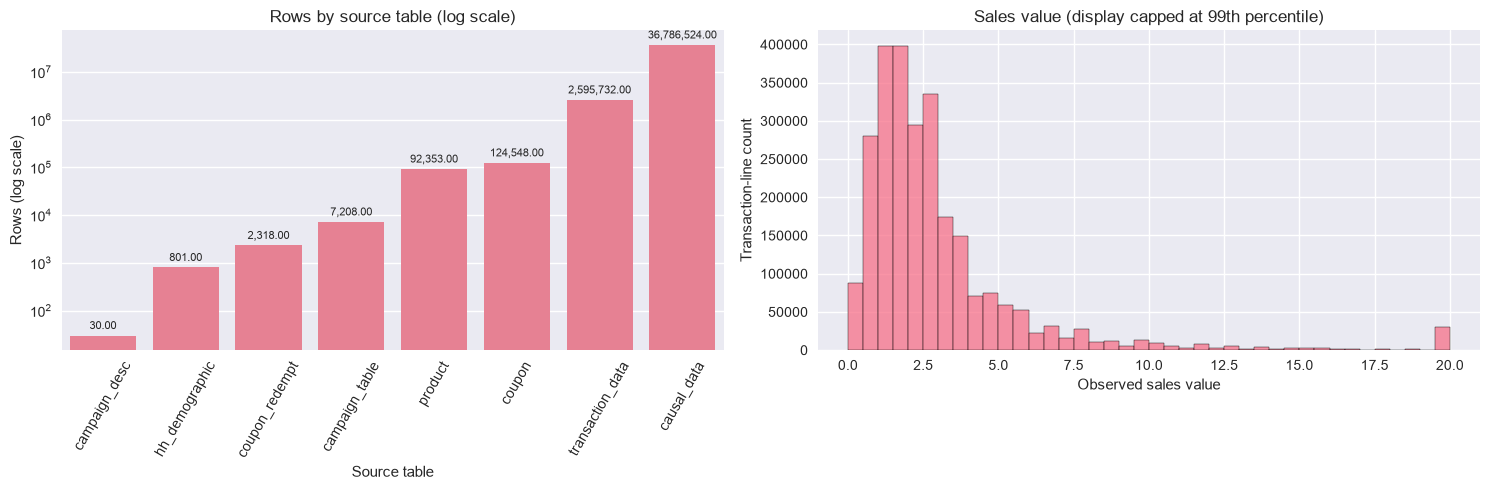

In [13]:
rows = pd.DataFrame(quality + [{'table':'transaction_data','rows':len(transactions),'columns':transactions.shape[1],'null_cells':0,'exact_duplicates':int(transactions.duplicated().sum())},{'table':'causal_data','rows':causal_rows,'columns':5,'null_cells':int(causal_nulls.sum()),'exact_duplicates':causal_chunk_duplicates}])
fig, axes = plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=rows.sort_values('rows'), x='table', y='rows', ax=axes[0]); axes[0].set_yscale('log'); axes[0].set(title='Rows by source table (log scale)', xlabel='Source table', ylabel='Rows (log scale)'); axes[0].tick_params(axis='x',rotation=60); add_bar_labels(axes[0])
sns.histplot(transactions.SALES_VALUE.clip(upper=transactions.SALES_VALUE.quantile(.99)),bins=40,ax=axes[1]); axes[1].set(title='Sales value (display capped at 99th percentile)',xlabel='Observed sales value',ylabel='Transaction-line count')
plt.tight_layout(); plt.show()

## Problem Statement

Determine whether the supplied files support reproducible promotion analysis without assuming keys, units, or experimental assignment. This notebook has no inferential question: deterministic data-quality checks do not have a meaningful H0/H1, alpha, power, sample-size, effect size, or confidence interval.

## Question 1 — Are source tables structurally usable and joinable?

In [14]:
display(pd.DataFrame({'check':['files present','transaction exact duplicates','product key unique','unmatched product joins','raw row count preserved'],'result':[inventory.exists.all(),int(transactions.duplicated().sum()),products.PRODUCT_ID.is_unique,unmatched_products,len(transaction_product)==len(transactions)]}))

,check,result
0,files present,True
1,transaction exact duplicates,0
2,product key unique,True
3,unmatched product joins,0
4,raw row count preserved,True


## Question 2 — What cleaning decisions are defensible?

In [15]:
display(pd.DataFrame([
 ['Missing rows','Count first; drop only missing rows',len(transactions)-len(transactions.dropna())],
 ['Exact duplicates','Deduplicate exact rows only',int(transactions.duplicated().sum())],
 ['Quantity extremes','Retain; use robust statistics',0],
 ['Positive discount adjustments','Retain source; exclude from derived discount amount',int((transactions.RETAIL_DISC>0).sum())]], columns=['issue','decision','affected_count']))

,issue,decision,affected_count
0,Missing rows,Count first; drop only missing rows,0
1,Exact duplicates,Deduplicate exact rows only,0
2,Quantity extremes,Retain; use robust statistics,0
3,Positive discount adjustments,Retain source; exclude from derived discount a...,36


## Summary

- All eight source files were inspected.
- The full transaction row count was preserved after explicit checks.
- Product enrichment passed a many-to-one join validation.
- A compressed processed table and audit manifests were created.

## Insights

- Extreme quantities are retained; robust summaries are required.
- Derived discounts use negative adjustments only.
- Costs/margins are absent, so profit is not analyzed.
- Promotion comparisons are observational, not causal.